<a href="https://colab.research.google.com/github/harpaleshreyash7-prog/EDA_Project_/blob/main/EDA_House_price.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# House Price EDA
## Introduction
This project analyses house prices.

In [ ]:
import pandas as pd

df = pd.read_csv("train.csv")

print("Dataset loaded successfully!")




Dataset loaded successfully!


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)


print(df.shape)          # expect (1460, 81)
display(df.head())
df.info()

missing = df.isnull().sum().sort_values(ascending=False)
missing = missing[missing > 0]
display(pd.DataFrame({"count": missing,
                      "percent": (missing / len(df) * 100).round(2)}))
print("Columns with missing values:", len(missing))

(1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

,count,percent
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageQual,81,5.55
GarageFinish,81,5.55
GarageType,81,5.55


Columns with missing values: 19


In [ ]:
numeric_cols = df.select_dtypes(include="number").columns.drop("Id").tolist()
categorical_cols = df.select_dtypes(include="object").columns.tolist()

order = ["Po", "Fa", "TA", "Gd", "Ex"]
for c in ["ExterQual", "KitchenQual"]:
    df[c] = pd.Categorical(df[c], categories=order, ordered=True)

summary = pd.DataFrame({
    "column": df.columns,
    "type": df.dtypes.astype(str).values,
    "n_unique": df.nunique().values,
    "examples": [df[c].dropna().unique()[:3].tolist() for c in df.columns]
})
display(summary)

,column,type,n_unique,examples
0,Id,int64,1460,"[1, 2, 3]"
1,MSSubClass,int64,15,"[60, 20, 70]"
2,MSZoning,object,5,"[RL, RM, C (all)]"
3,LotFrontage,float64,110,"[65.0, 80.0, 68.0]"
4,LotArea,int64,1073,"[8450, 9600, 11250]"
...,...,...,...,...
76,MoSold,int64,12,"[2, 5, 9]"
77,YrSold,int64,5,"[2008, 2007, 2006]"
78,SaleType,object,9,"[WD, New, COD]"
79,SaleCondition,object,6,"[Normal, Abnorml, Partial]"


In [ ]:
# 1. Duplicates (ignore Id, because it is always unique)
dup_count = df.drop(columns="Id").duplicated().sum()
print("Duplicates:", dup_count)
if dup_count > 0:
    df = df.drop_duplicates(subset=df.columns.drop("Id"))
    print(df.shape)

# 2. Inconsistent labels in text columns
for c in categorical_cols:
    vals = df[c].dropna().unique()
    stripped = pd.Series(vals).str.strip().str.lower().nunique()
    if stripped != len(vals):
        print("Problem in", c, vals)
# if nothing prints, labels are consistent; say so in your notes

# 3. "NA" means "feature absent", not unknown
none_cols = ["PoolQC","MiscFeature","Alley","Fence","FireplaceQu",
             "GarageType","GarageFinish","GarageQual","GarageCond",
             "BsmtQual","BsmtCond","BsmtExposure","BsmtFinType1","BsmtFinType2"]
for c in none_cols:
    df[c] = df[c].fillna("None")

# 4. Genuinely missing values
df["LotFrontage"] = df.groupby("Neighborhood")["LotFrontage"] \
                      .transform(lambda s: s.fillna(s.median()))
df["GarageYrBlt"] = df["GarageYrBlt"].fillna(0)      # no garage
df["MasVnrArea"]  = df["MasVnrArea"].fillna(0)
df["MasVnrType"]  = df["MasVnrType"].fillna("None")
df["Electrical"]  = df["Electrical"].fillna(df["Electrical"].mode()[0])

print("Remaining missing:", df.isnull().sum().sum())

# 5. Impossible values
print("Built after sold:", (df["YearBuilt"] > df["YrSold"]).sum())
print("Negative areas:", (df[["GrLivArea","LotArea","TotalBsmtSF"]] < 0).sum().sum())

Duplicates: 0
Remaining missing: 0
Built after sold: 0
Negative areas: 0


In [ ]:
display(df[numeric_cols].describe().T)

for col in ["SalePrice", "GrLivArea", "LotArea"]:
    s = df[col]
    print(f"\n--- {col} ---")
    print("mean", round(s.mean(),2), "| median", s.median(), "| mode", s.mode()[0])
    print("std", round(s.std(),2), "| var", round(s.var(),2))
    print("range", s.max()-s.min(), "| IQR", s.quantile(.75)-s.quantile(.25))
    print("skew", round(s.skew(),2), "| kurtosis", round(s.kurt(),2))
    print("Right skewed" if s.mean() > s.median() else "Left skewed")

for col in ["Neighborhood", "HouseStyle"]:
    print(df[col].value_counts(), "\nMode:", df[col].mode()[0])

,count,mean,std,min,25%,50%,75%,max
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1460.0,70.199658,22.431902,21.0,60.00,70.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1460.0,103.117123,180.731373,0.0,0.00,0.0,164.25,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0
BsmtFinSF2,1460.0,46.549315,161.319273,0.0,0.00,0.0,0.00,1474.0



--- SalePrice ---
mean 180921.2 | median 163000.0 | mode 140000
std 79442.5 | var 6311111264.3
range 720100 | IQR 84025.0
skew 1.88 | kurtosis 6.54
Right skewed

--- GrLivArea ---
mean 1515.46 | median 1464.0 | mode 864
std 525.48 | var 276129.63
range 5308 | IQR 647.25
skew 1.37 | kurtosis 4.9
Right skewed

--- LotArea ---
mean 10516.83 | median 9478.5 | mode 7200
std 9981.26 | var 99625649.65
range 213945 | IQR 4048.0
skew 12.21 | kurtosis 203.24
Right skewed
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
SWISU       25
StoneBr     25
Blmngtn     17
MeadowV     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name: count, dtype: int64 
Mode: NAmes
HouseStyle
1Story    726
2Story    445
1.5Fin    154
SLvl       65
SFoyer     37
1.5Unf     14
2.5Unf     

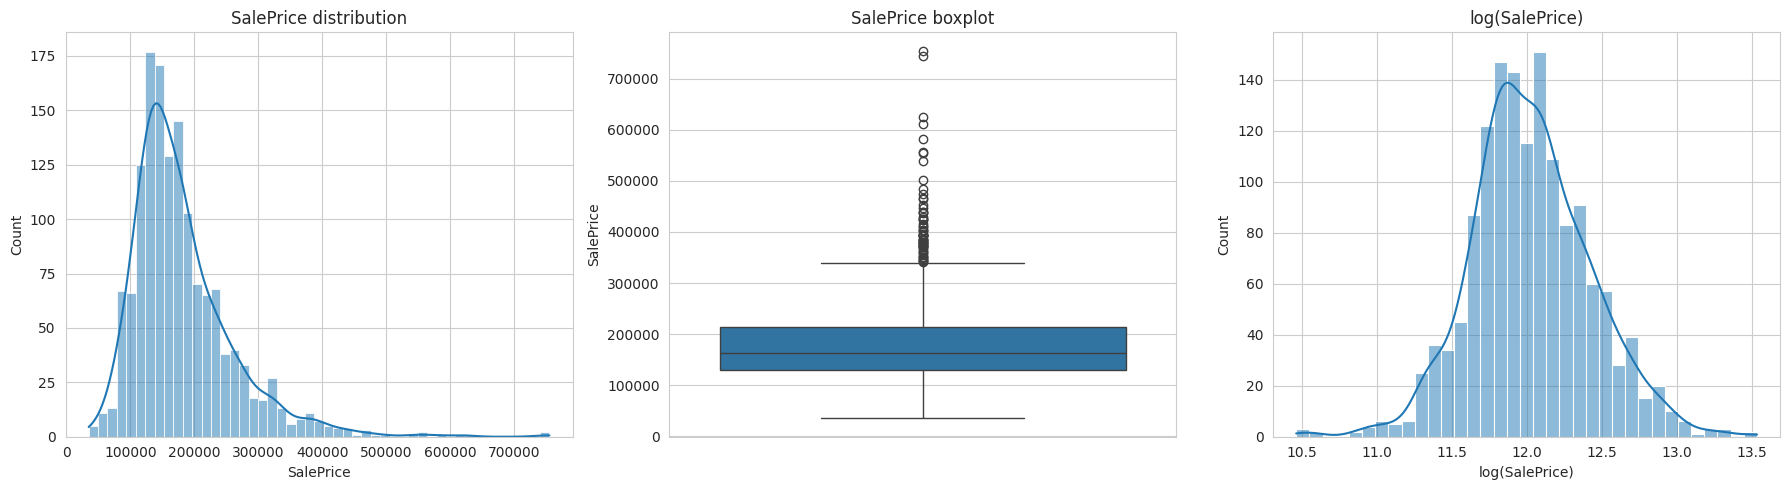

Skew before: 1.8828757597682129 after: 0.12133506220520406


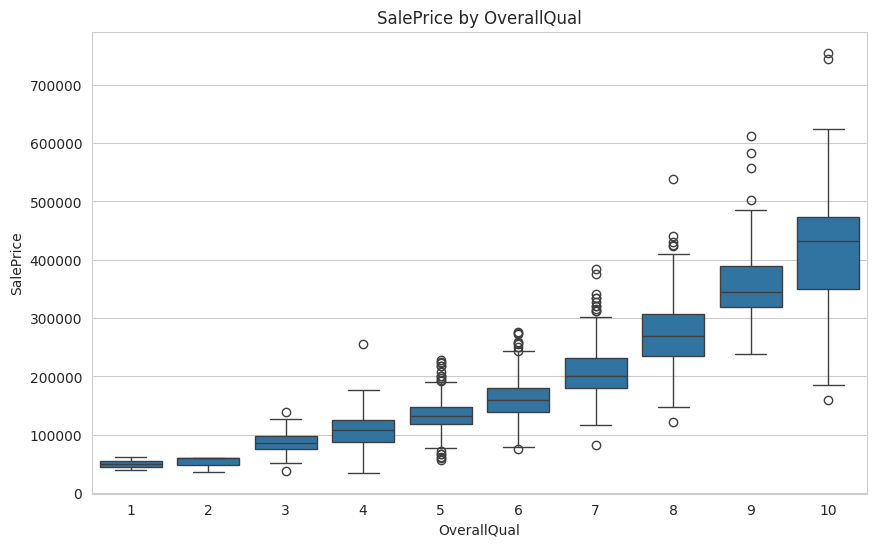

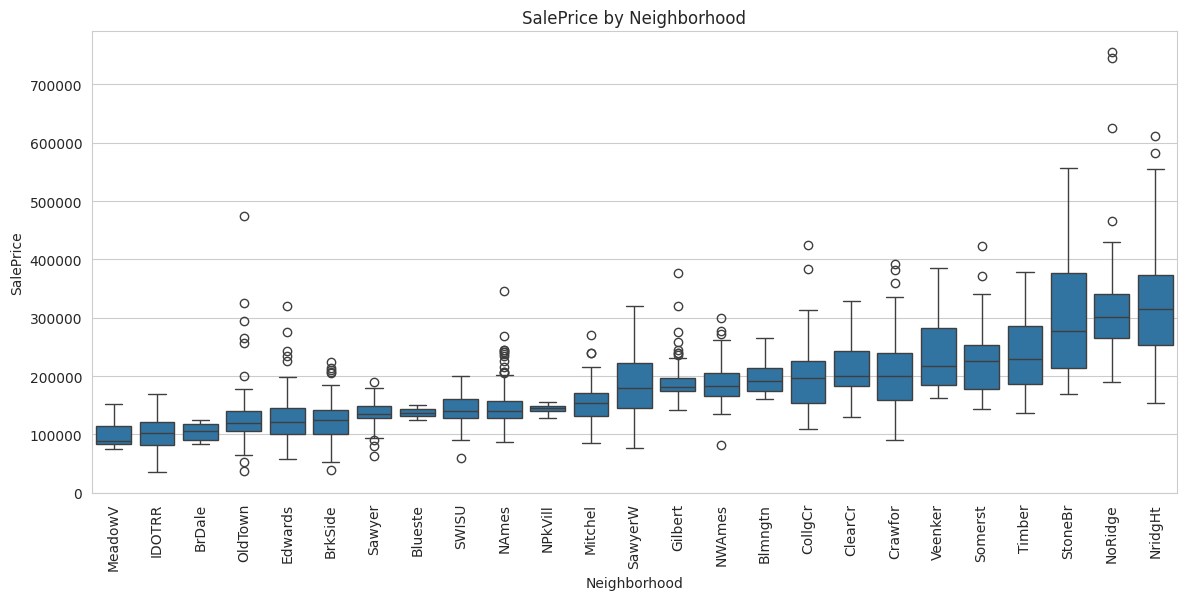

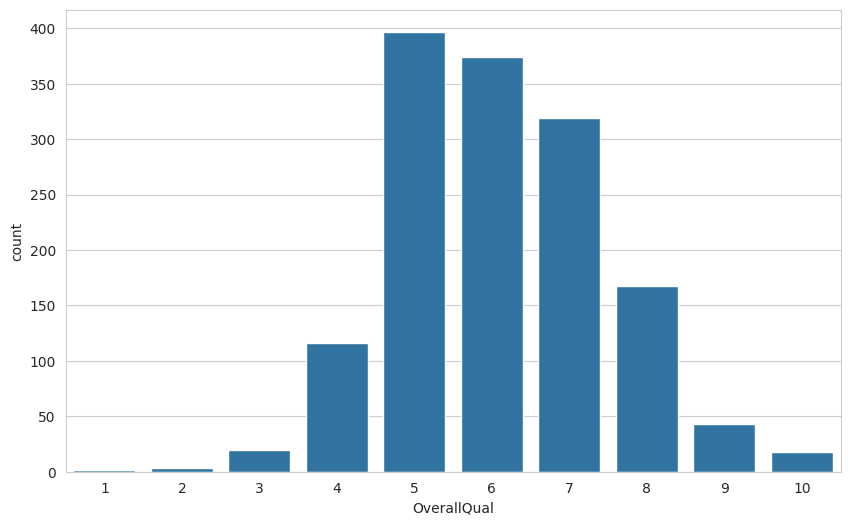

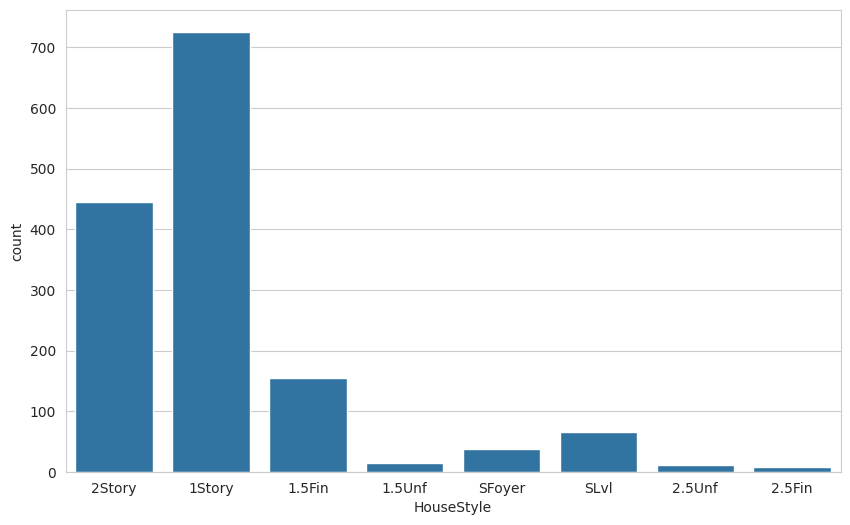

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(df["SalePrice"], kde=True, ax=ax[0])
ax[0].set(title="SalePrice distribution", xlabel="SalePrice", ylabel="Count")
sns.boxplot(y=df["SalePrice"], ax=ax[1]); ax[1].set_title("SalePrice boxplot")
sns.histplot(np.log(df["SalePrice"]), kde=True, ax=ax[2])
ax[2].set(title="log(SalePrice)", xlabel="log(SalePrice)")
plt.tight_layout(); plt.show()
print("Skew before:", df["SalePrice"].skew(), "after:", np.log(df["SalePrice"]).skew())

sns.boxplot(x="OverallQual", y="SalePrice", data=df)
plt.title("SalePrice by OverallQual"); plt.show()

order_n = df.groupby("Neighborhood")["SalePrice"].median().sort_values().index
plt.figure(figsize=(14,6))
sns.boxplot(x="Neighborhood", y="SalePrice", data=df, order=order_n)
plt.xticks(rotation=90); plt.title("SalePrice by Neighborhood"); plt.show()

sns.countplot(x="OverallQual", data=df); plt.show()
sns.countplot(x="HouseStyle", data=df); plt.show()

In [ ]:
cov_matrix  = df[numeric_cols].cov()
corr_matrix = df[numeric_cols].corr()

top_corr = corr_matrix["SalePrice"].abs().sort_values(ascending=False)
print(top_corr.head(11))          # first one is SalePrice itself

for f in top_corr.index[1:4]:
    print(f, "cov:", cov_matrix.loc[f, "SalePrice"],
             "corr:", corr_matrix.loc[f, "SalePrice"])

# Optional: Spearman for ordinal columns
print(df[["OverallQual","SalePrice"]].corr(method="spearman"))

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64
OverallQual cov: 86904.12583679947 corr: 0.7909816005838053
GrLivArea cov: 29581866.743236605 corr: 0.7086244776126515
GarageCars cov: 38020.18135897171 corr: 0.6404091972583519
             OverallQual  SalePrice
OverallQual     1.000000   0.809829
SalePrice       0.809829   1.000000


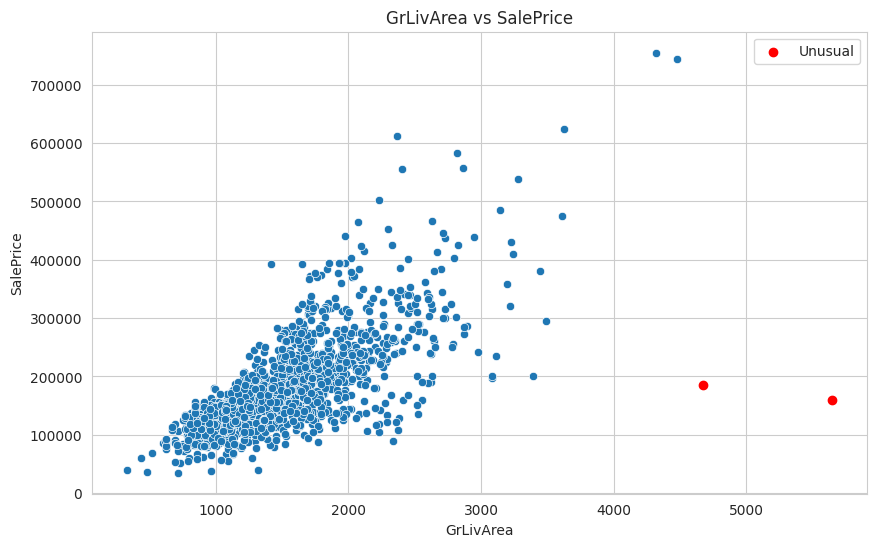

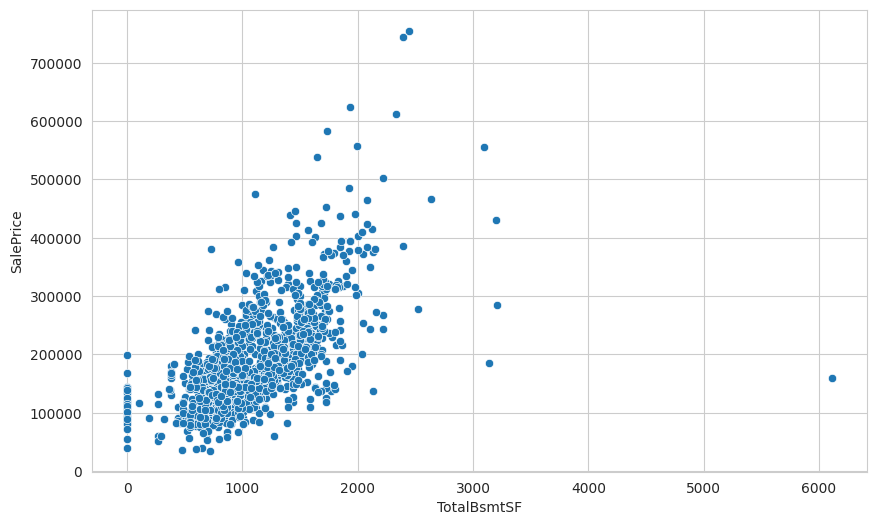

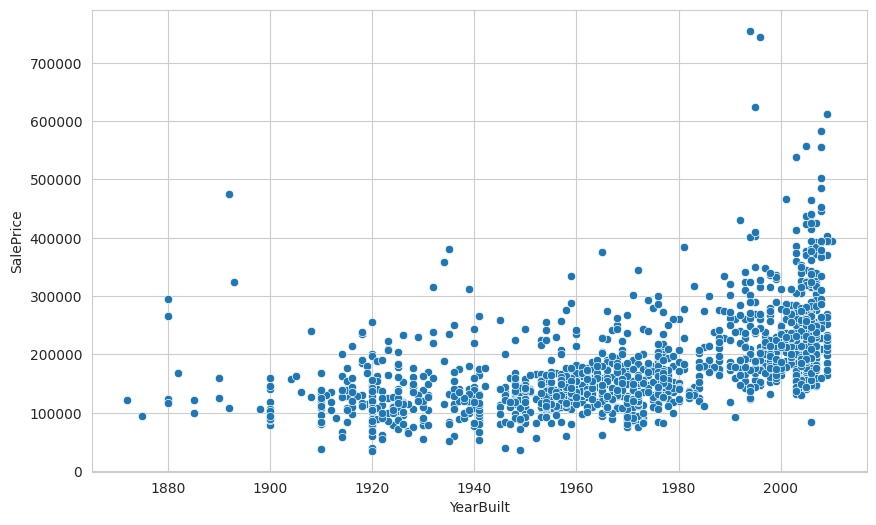

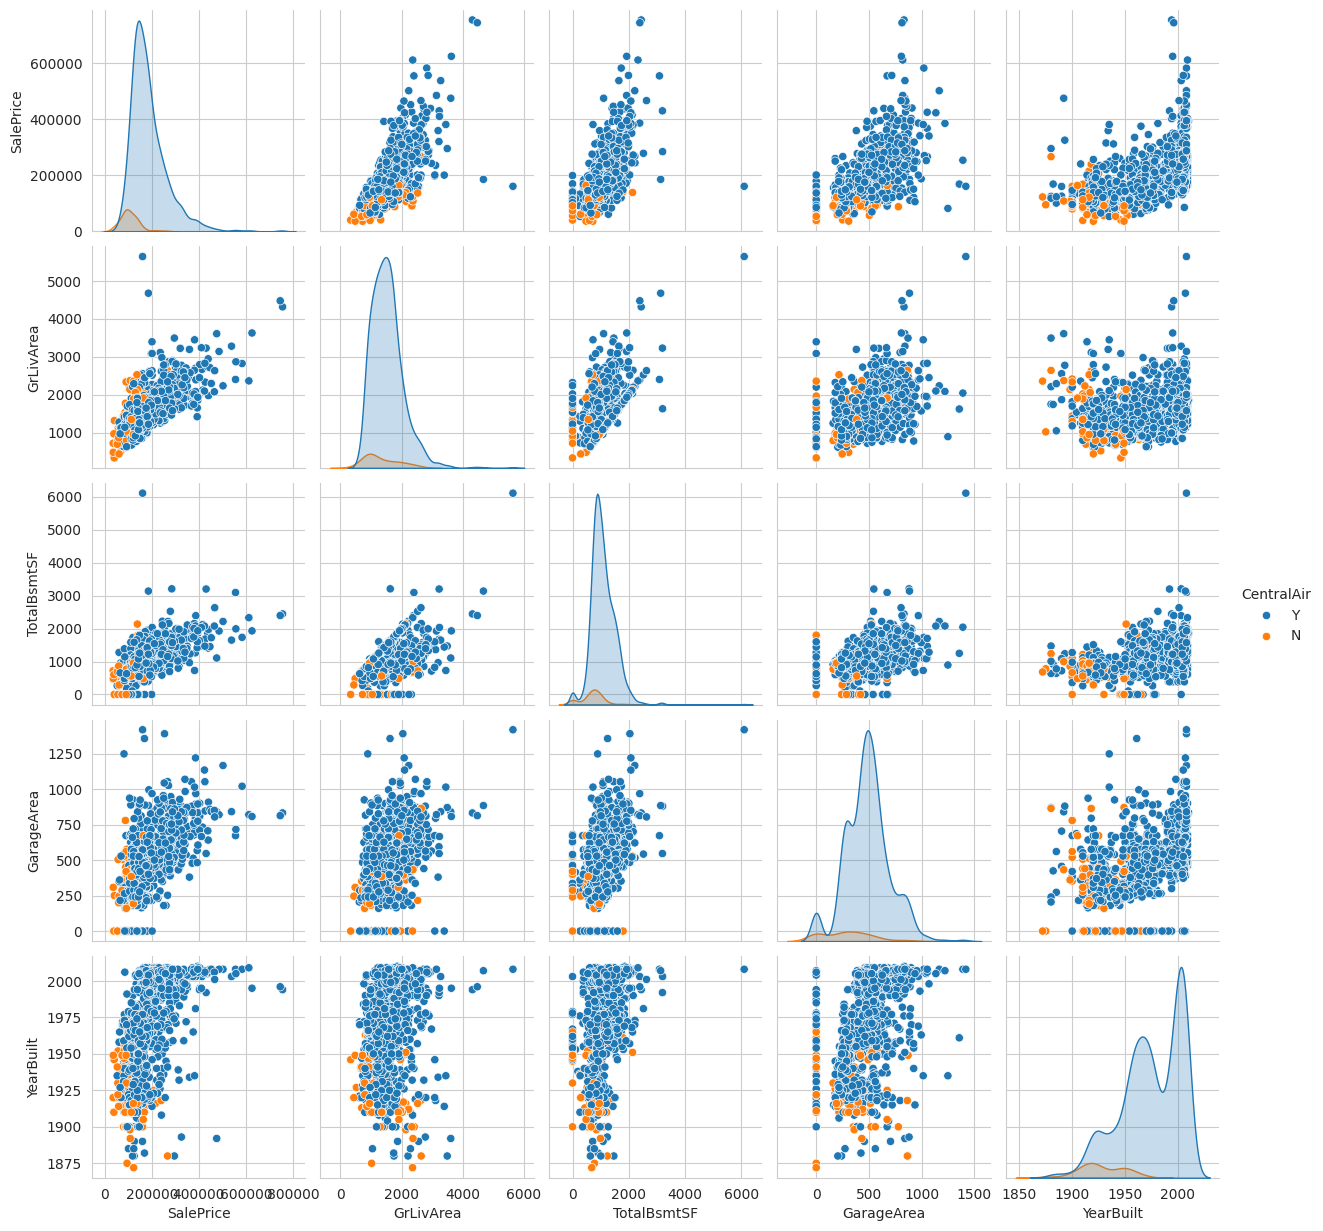

In [ ]:
sns.scatterplot(x="GrLivArea", y="SalePrice", data=df)
out = df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)]
plt.scatter(out["GrLivArea"], out["SalePrice"], color="red", label="Unusual")
plt.title("GrLivArea vs SalePrice"); plt.legend(); plt.show()

sns.scatterplot(x="TotalBsmtSF", y="SalePrice", data=df); plt.show()
sns.scatterplot(x="YearBuilt", y="SalePrice", data=df); plt.show()

selected = ["SalePrice","GrLivArea","TotalBsmtSF","GarageArea","YearBuilt"]
sns.pairplot(df[selected + ["CentralAir"]], hue="CentralAir", diag_kind="kde")
plt.show()

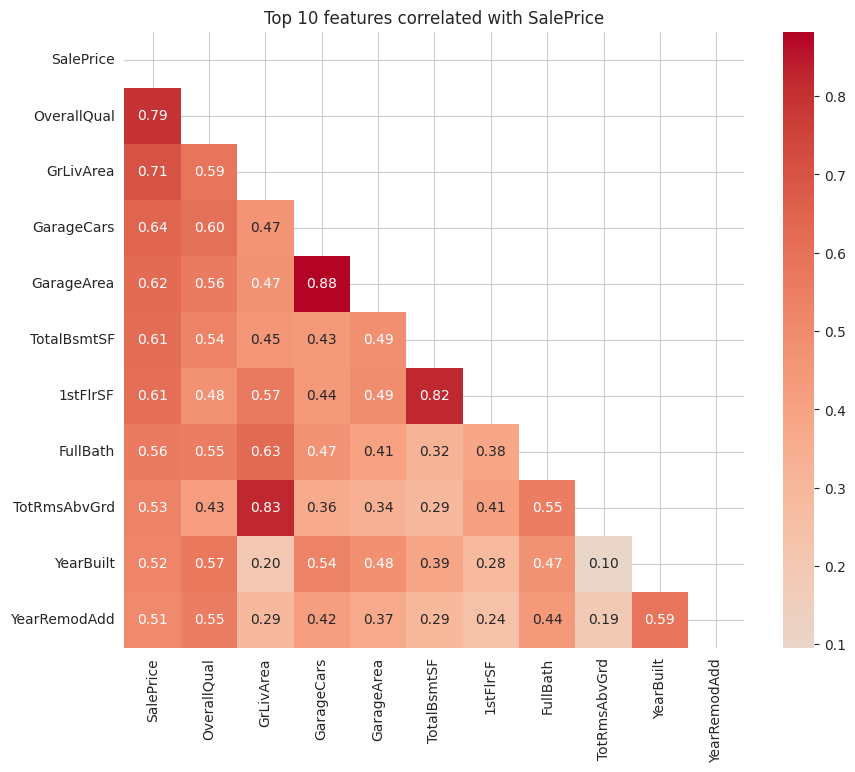

In [ ]:
top10 = top_corr.head(11).index          # includes SalePrice
corr_top = df[top10].corr()
mask = np.triu(np.ones_like(corr_top, dtype=bool))
plt.figure(figsize=(10, 8))
sns.heatmap(corr_top, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, mask=mask)
plt.title("Top 10 features correlated with SalePrice"); plt.show()

GrLivArea | IQR: 31 | Z-score: 16 | overlap: 16


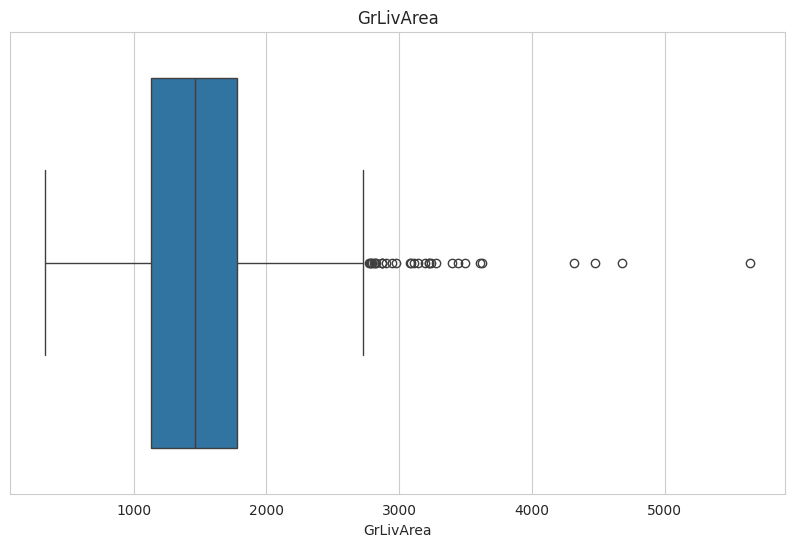

SalePrice | IQR: 61 | Z-score: 22 | overlap: 22


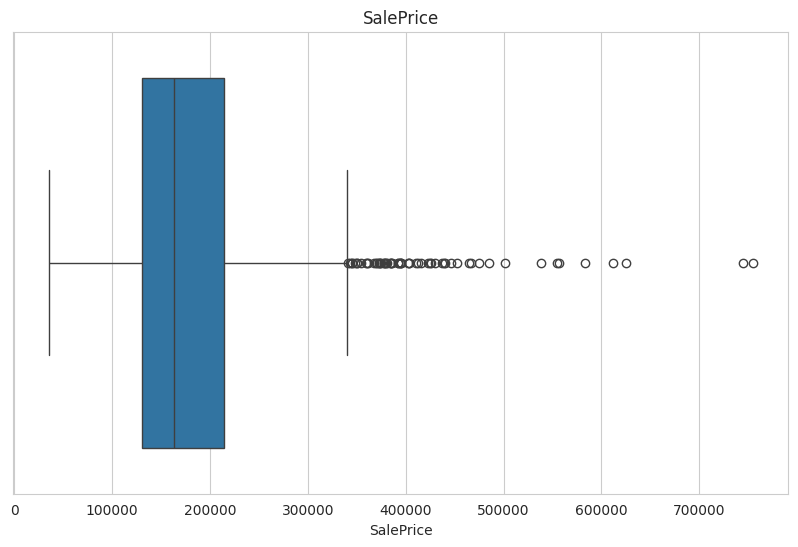

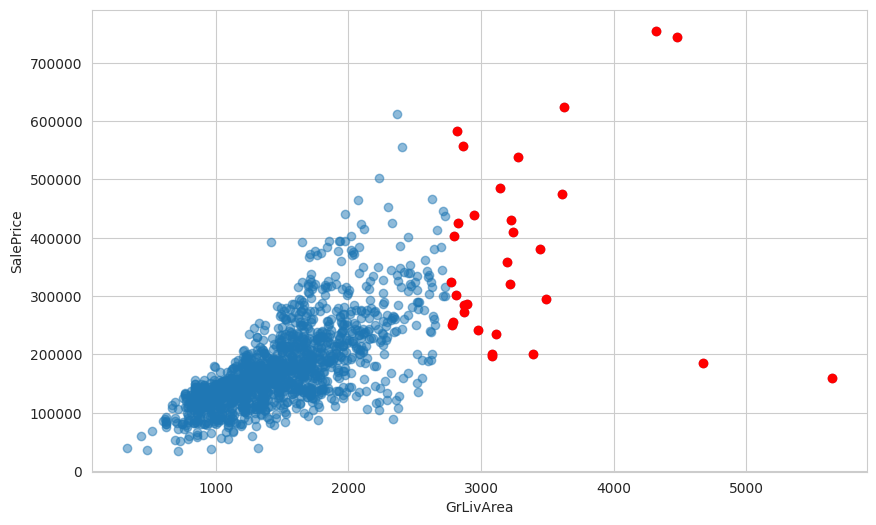

(1460, 81) -> (1458, 81)


In [ ]:
def iqr_outliers(s):
    q1, q3 = s.quantile(.25), s.quantile(.75)
    iqr = q3 - q1
    return s[(s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)]

def zscore_outliers(s, threshold=3):
    z = (s - s.mean()) / s.std()
    return s[z.abs() > threshold]

for col in ["GrLivArea", "SalePrice"]:
    a, b = iqr_outliers(df[col]), zscore_outliers(df[col])
    print(col, "| IQR:", len(a), "| Z-score:", len(b),
          "| overlap:", len(set(a.index) & set(b.index)))
    sns.boxplot(x=df[col]); plt.title(col); plt.show()

flag = iqr_outliers(df["GrLivArea"]).index
plt.scatter(df["GrLivArea"], df["SalePrice"], alpha=.5)
plt.scatter(df.loc[flag,"GrLivArea"], df.loc[flag,"SalePrice"], color="red")
plt.xlabel("GrLivArea"); plt.ylabel("SalePrice"); plt.show()

# Decision: remove the 2 huge-but-cheap houses (likely unusual sales)
df_clean = df[~((df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000))]
print(df.shape, "->", df_clean.shape)

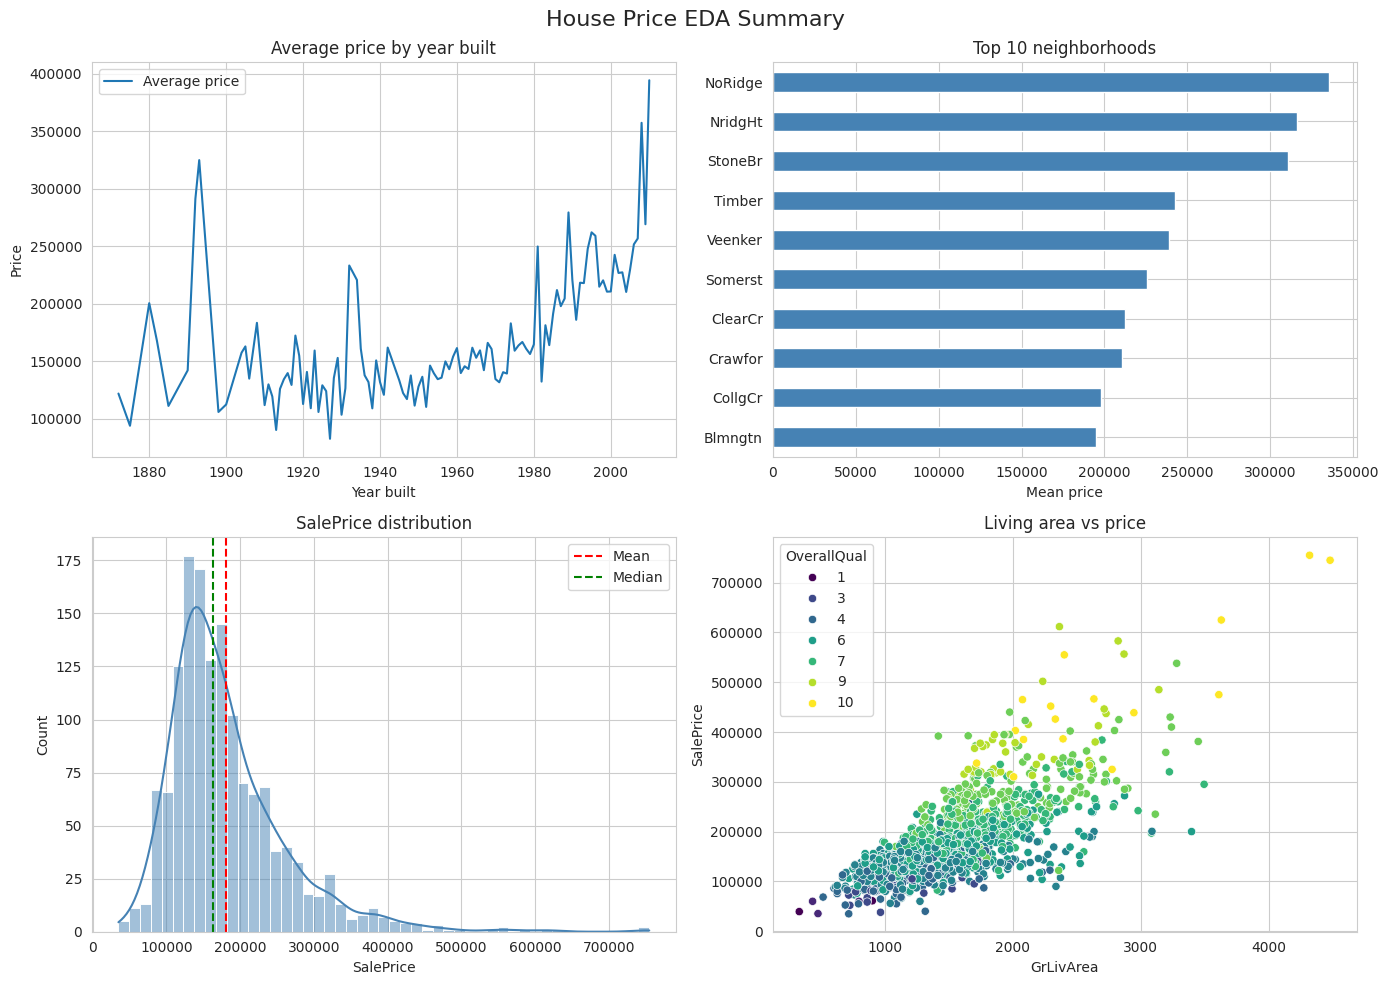

In [ ]:
d = df_clean
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# Panel 1: line
d.groupby("YearBuilt")["SalePrice"].mean().plot(ax=ax[0,0], label="Average price")
ax[0,0].set(title="Average price by year built", xlabel="Year built", ylabel="Price")
ax[0,0].legend()

# Panel 2: horizontal bars
d.groupby("Neighborhood")["SalePrice"].mean().nlargest(10).sort_values() \
 .plot(kind="barh", ax=ax[0,1], color="steelblue")
ax[0,1].set(title="Top 10 neighborhoods", xlabel="Mean price", ylabel="")

# Panel 3: histogram with mean and median
sns.histplot(d["SalePrice"], kde=True, ax=ax[1,0], color="steelblue")
ax[1,0].axvline(d["SalePrice"].mean(), color="red", ls="--", label="Mean")
ax[1,0].axvline(d["SalePrice"].median(), color="green", ls="--", label="Median")
ax[1,0].set_title("SalePrice distribution"); ax[1,0].legend()

# Panel 4: scatter coloured by quality
sns.scatterplot(x="GrLivArea", y="SalePrice", hue="OverallQual",
                palette="viridis", data=d, ax=ax[1,1])
ax[1,1].set_title("Living area vs price")

fig.suptitle("House Price EDA Summary", fontsize=16)
plt.tight_layout()
plt.savefig("eda_dashboard.png", dpi=150)
plt.show()